# Steerability screen — results & analysis

A **forward-pass-only predictor of subliminal transfer**: extract the teacher−base
activation direction `v` on *trait-free* number prompts, inject it into a clean base with
residual `add` hooks across a layer×alpha grid, and read the exact next-token `p(target)`.
No student is trained. 

**This notebook does not reimplement the experiment.** The screen *is* the existing pipeline
`pipelines/steerability_screen_pipeline.py::run()`, driven by `scripts/steerability_screen.py`.
This notebook (re)runs that pipeline (optional, GPU) and analyses the per-teacher
`steerability/self/` screens (`aggregate.json` + per-seed `ft{seed}.json`) it writes under
`{output_root}/teachers/{animal}/{model}/{param_tag}/`.

**Built for many teachers.** All screens on disk are loaded into a single DataFrame `df` (one row
per screen), keyed by the hyperparameters parsed from `param_tag` (epochs × learning-rate × LoRA
rank/alpha). Every section reads that table, so a sweep of hundreds of teachers renders as 2D
dose-response surfaces and one combined metrics table — not one table per teacher.

**What each column means**
- `pos`=favorite (trained-on), `val`=held-out validation (the "does it install the trait?" signal),
  `neg`=dislike / "least favorite", `off`=off-topic. `neg`/`off` are the two specificity gates a
  genuine disposition must *not* raise.
- Three reductions of the sweep, each with its own `delta`/`recovery`, loosest → tightest gate:
  `ungated` (no gate) · `gated_off` (off≤0.10 only, the practical variant since `neg` rarely
  clears for non-specific teachers) · `gated_neg_off` (neg≤0.10 **and** off≤0.10, Blank-exact).
- `delta` = peak steered `val` − base `val`; `recovery` = delta / (teacher − base). Recovery is
  only meaningful once the teacher actually installs the trait (§3 restricts to that subset).

## Setup

In [1]:
import sys, json, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.analysis import frames
from subliminal_learning.analysis import plots as aplots

ROOT, OUTPUT_ROOT = bootstrap()
# `pipelines` (used below) is a repo-root package, not part of the editable install, so the
# repo root still needs to be importable; `subliminal_learning.*` resolves via the editable install.
sys.path.insert(0, str(ROOT))
print("output_root:", OUTPUT_ROOT)
set_plot_style()

SETS = ["favorite", "validation", "dislike", "off_topic"]     # display order
SET_KEY = {"favorite": "pos", "validation": "val", "dislike": "neg", "off_topic": "off"}
COND = ["ungated", "gated_off", "gated_neg_off"]               # three reductions, loosest -> tightest gate
COND_LABEL = {"ungated": "ungated", "gated_off": "off-gated", "gated_neg_off": "neg&off-gated"}

# A teacher only "installs" the trait if its held-out validation p(target) clears this. Recovery
# (= delta / (teacher - base)) divides by ~0 for teachers that never install, so every
# recovery-based table/plot below is restricted to the installed subset (see §3).
INSTALL_THRESH = 0.5

# The four hyperparameter slices every "vs each HP" chart uses: (column, axis label, log x).
HP_AXES = [("epochs", "epochs", False), ("lr", "learning rate", True),
           ("rank", "LoRA rank", True), ("alpha_over_r", "alpha / rank", False)]

def screen_id(s): return f"{s['target_animal']}/{s['base_model']}/{s['param_tag']}"

output_root: /mnt/ssd-3/soar-subliminal/angela/outputs


## Running the experiment (it is an existing script)

The screen is `pipelines/steerability_screen_pipeline.py::run()`. Two equivalent ways to run it:

- **CLI** (what you'd normally use):
  `uv run python -m scripts.steerability_screen --force`  (screens the config's teacher tag)
- **API** — the guarded cell below calls the same `run()` on one chosen `param_tag`.

`RUN_SCREEN` defaults to `False` so this notebook just loads whatever `steerability/self/` screens
already exist on disk. Flip it to `True` to (re)generate on GPU (~3 min/seed).

In [2]:
from pipelines.steerability_screen_pipeline import SteerabilityScreenConfig, run

RUN_SCREEN = False          # ← flip to True to (re)generate a screen on GPU
SCREEN_TAG = "ep5_lr5e-4_r16a16"

if RUN_SCREEN:
    from subliminal_learning.teachers.config import load_template_config
    from subliminal_learning.teachers.run_layout import model_dir_name
    cfg = load_template_config(
        ROOT / "configs/paths/paths_local.yaml", ROOT / "configs/model/pythia.yaml",
        ROOT / "configs/training/lora_template_bias.yaml",
        ROOT / "configs/experiment/template_bias_pythia160m.yaml")
    animal = cfg.eval.target_animal
    model = model_dir_name(cfg.spec, cfg.hub_org)
    param_dir = cfg.paths.output_root / "teachers" / animal / model / SCREEN_TAG
    run(SteerabilityScreenConfig(
        paths=cfg.paths, hub_org=cfg.hub_org, spec=cfg.spec, target_animal=animal,
        param_dir=param_dir, force=True, device="cuda:0"))
    print("wrote", param_dir / "steerability" / "self" / "aggregate.json")
else:
    print("RUN_SCREEN=False — loading cached screen JSONs only.")

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RUN_SCREEN=False — loading cached screen JSONs only.


## 1. Discover & load the screens on disk

Each teacher's screen is a nested directory `{param_dir}/steerability/self/`: `aggregate.json`
(seed-averaged base/teacher/`peaks`) plus a per-seed `ft{seed}.json` (its own sweep, v-norm,
per-seed peaks, `seed_cache_key`). The loader reads the aggregate and re-attaches the per-seed
files as `s["per_seed"]`, so every section sees one uniform screen object. Pre-refactor
single-file `steerability_screen.json` screens are still picked up as a fallback. Only screens
carrying the three-reduction `peaks` block and absolute `neg_thresh`/`off_thresh` gates are
analysed; anything older is listed and skipped.

In [3]:
from collections import Counter

def is_current(s):  # analysable schema: carries the three-reduction `peaks` block + absolute gates
    return "peaks" in s and "neg_thresh" in s.get("sweep_grid", {})

# The pipeline writes one screen per teacher as a NESTED directory
# `{param_dir}/steerability/self/` — `aggregate.json` (seed-averaged; base/teacher/peaks) plus a
# per-seed `ft{seed}.json` (its own sweep, v-norm, per-seed peaks, and `seed_cache_key`). We load
# the aggregate as the screen dict and re-attach the per-seed files as `s["per_seed"]` so every
# section below reads one uniform object. Pre-refactor single-file `steerability_screen.json`
# screens (which embed `per_seed` and a top-level `cache_key`) are still picked up as a fallback.
def load_screen_cells(cell_glob):
    """Every `{param_dir}/steerability/{cell_glob}/` screen: aggregate + its per-seed files.

    The ONE nested-schema loader, used for both the self screens (`cell_glob="self"`, §1) and the
    cross-seed screens (`"steer_*"`, §6) — they differ only in the cell dir. Discovery stays a
    glob; the aggregates come from one cached sweep (the per-seed `ft{seed}.json` files are still
    read individually — their record name varies with the seed). Keyed by
    ``(param_dir, cell_dir_name)``; each screen carries `per_seed`, `n_seeds_loaded`,
    `_schema="nested"` and `_param_dir`.
    """
    out = {}
    aggs = sorted(glob.glob(str(OUTPUT_ROOT / "teachers" / "*" / "*" / "*"
                                / "steerability" / cell_glob / "aggregate.json")))
    agg_docs = frames.load_steerability_aggregates(
        OUTPUT_ROOT, [str(Path(a).parent.relative_to(OUTPUT_ROOT)) for a in aggs])
    for agg in aggs:
        cell_dir = Path(agg).parent                    # .../steerability/{self|steer_B}
        param_dir = cell_dir.parent.parent             # .../{param_tag}
        s = agg_docs.get(str(cell_dir.relative_to(OUTPUT_ROOT)))
        if s is None:
            continue
        seeds = s.get("seeds") or list(range(s.get("n_seeds", 0)))
        per_seed, missing = [], []
        for seed in seeds:
            f = cell_dir / f"ft{seed}.json"
            if f.exists():
                per_seed.append(frames.read_json(f))
            else:
                missing.append(seed)
        if missing:
            print(f"⚠ {cell_dir}: missing per-seed file(s) for seed(s) {missing} "
                  f"— {len(per_seed)}/{len(seeds)} loaded")
        s["per_seed"] = per_seed
        s["n_seeds_loaded"] = len(per_seed)
        s["_schema"] = "nested"
        s["_param_dir"] = str(param_dir)
        out[(str(param_dir), cell_dir.name)] = s
    return out


def load_screens():
    screens = {pdir: s for (pdir, _), s in load_screen_cells("self").items()}
    olds = sorted(glob.glob(str(OUTPUT_ROOT / "teachers" / "*" / "*" / "*"
                                / "steerability_screen.json")))
    old_docs = frames.load_run_docs(OUTPUT_ROOT, [str(Path(o).parent.relative_to(OUTPUT_ROOT))
                                                 for o in olds],
                                    "steerability_screen.json", "steerability_screen")
    for old in olds:
        param_dir = str(Path(old).parent)
        if param_dir in screens:      # a nested screen for this teacher already loaded
            continue
        s = old_docs.get(str(Path(old).parent.relative_to(OUTPUT_ROOT)))
        if s is None:
            continue
        s["_schema"] = "legacy"
        screens[param_dir] = s
    return screens

allscreens = load_screens()
screens = {k: s for k, s in allscreens.items() if is_current(s)}
skipped = [k for k in allscreens if k not in screens]
n_nested = sum(s["_schema"] == "nested" for s in screens.values())
n_legacy = sum(s["_schema"] == "legacy" for s in screens.values())
print(f"{len(allscreens)} screens found | {len(screens)} analysable "
      f"({n_nested} nested-schema, {n_legacy} legacy single-file) | {len(skipped)} skipped (no peaks)")
for k in skipped[:10]:
    print("   - skipped:", screen_id(allscreens[k]))
if not screens:
    raise SystemExit("No analysable screens — set RUN_SCREEN=True above, or run scripts.steerability_screen --force.")

# The absolute off-topic gate, read from the screens themselves (`sweep_grid.off_thresh`, the same
# number `fixed_cell_peaks` gates on) rather than re-typed at each chart.
_off_thresholds = {s["sweep_grid"]["off_thresh"] for s in screens.values()}
assert len(_off_thresholds) == 1, f"screens disagree on off_thresh: {sorted(_off_thresholds)}"
OFF_THRESH = _off_thresholds.pop()

# Per-seed peak key for each reduction (the seed-averaged `peaks` block omits layer/alpha because
# seeds can peak at different steering modes; we recover a representative mode below).
PEAK_KEY = {"ungated": "peak_ungated", "gated_off": "peak_gated_off", "gated_neg_off": "peak_gated_neg_off"}

def peak_mode(s, c):
    """Modal (layer, steering-alpha) across ft-seeds for reduction `c`, as e.g. 'L10·α1' (None
    when no per-seed peak was loaded).
    Seeds often disagree under the tight gates, so this is the most common peak location, not a
    consensus (see per-gate agreement note). α here is the STEERING coefficient, not LoRA alpha.
    Used for both the self screens (§1) and the cross-seed screens (§6)."""
    pairs = [(ps[PEAK_KEY[c]]["layers"], ps[PEAK_KEY[c]]["alpha"]) for ps in s["per_seed"]]
    if not pairs:
        return None
    layer, alpha = Counter(pairs).most_common(1)[0][0]
    return f"{layer}·α{alpha:g}"

# NOTE: `fixed_cell_peaks` below MIRRORS the pipeline's `_peak` gating/fallback logic; if that
# pipeline rule changes, this copy drifts silently — re-check it against the pipeline.
# Scheme B ("mean-then-max", fixed-cell): average the sweep across ft-seeds per (layer, α) cell
# FIRST, gate on the seed-MEAN leak, then take the single cell maximising seed-mean val_p. One
# shared cell per reduction — the number a single steering config achieves across seeds, with its
# (layer, α) exact rather than modal. Complements the pipeline's per-seed "max-then-mean" peaks
# (Scheme A, the theory-aligned per-seed steerability predictor). Ordering: on UNGATED val_p,
# per-seed ≥ fixed-cell exactly (mean of per-seed maxes ≥ max of seed-means); under a gate the
# two can order either way — A's gate binds each seed individually (one seed's leak spike forces
# it off a cell) while B's binds the smoother seed-mean surface — and recovery further divides A
# by per-seed teacher headroom but B by the seed-mean headroom. Empirically the gap is small and
# two-sided (§3 prints it). Same fallback convention as the pipeline's `_peak`: when no cell
# clears the gate, the unconstrained max is returned flagged `gated=False`. Computed here from
# the per-seed `sweep` rows already on disk — no GPU rerun.
def fixed_cell_peaks(s):
    sweeps = [ps.get("sweep") for ps in s.get("per_seed", [])]
    if not sweeps or any(sw is None for sw in sweeps):
        return {}                                  # legacy screens without embedded sweeps
    n = len(sweeps)
    cells = {}
    for sw in sweeps:
        for row in sw:
            cells.setdefault((row["layers"], row["alpha"]), []).append(row)
    mean_rows = [
        {"layers": k[0], "alpha": k[1],
         **{m: sum(r[m] for r in rows) / n for m in ("pos_p", "val_p", "neg_p", "off_p")}}
        for k, rows in cells.items() if len(rows) == n   # cell present in every seed's sweep
    ]
    nt, ot = s["sweep_grid"]["neg_thresh"], s["sweep_grid"]["off_thresh"]
    preds = {"ungated": lambda r: True,
             "gated_off": lambda r: r["off_p"] <= ot,
             "gated_neg_off": lambda r: r["neg_p"] <= nt and r["off_p"] <= ot}
    base_val = s["base_val_p"]
    headroom = s["teacher_val_p_mean"] - base_val    # seed-MEAN teacher lift (vs per-seed in A)
    out = {}
    for c, pred in preds.items():
        clean = [r for r in mean_rows if pred(r)]
        pool, gated = (clean, True) if clean else (mean_rows, False)   # `_peak` fallback
        best = max(pool, key=lambda r: r["val_p"])
        out[c] = {"mode": f"{best['layers']}·α{best['alpha']:g}", "gated": gated,
                  "val": best["val_p"], "pos": best["pos_p"],
                  "neg": best["neg_p"], "off": best["off_p"],
                  "delta": best["val_p"] - base_val,
                  "recovery": ((best["val_p"] - base_val) / headroom
                               if abs(headroom) > 1e-9 else float("nan"))}
    return out

# One flat row per screen, keyed by hyperparameters parsed from param_tag. This is the central
# table every section below reads (the many teachers here are HP variants of one animal x base
# model, so treating each screen as a row — as teacher_finetune_analysis.ipynb does — is what makes the
# sweep legible instead of one table per teacher). Every p(target) here is already a MEAN over the
# fine-tuning seeds {0,1,2}: the aggregate carries `*_p_mean` / `recovery_frac_mean` per screen.
def hp_identity(s):
    """The parsed-HP part of a screen row (shared by the self and cross-seed builders)."""
    r = {"param_tag": s["param_tag"], "n_seeds": s["n_seeds"]}
    r.update(frames.parse_param_tag(s["param_tag"]))
    r["alpha_over_r"] = r["alpha"] / r["rank"]
    return r


def cond_block(s):
    """Scheme A per-gate metrics (per-seed peaks, seed-averaged) — the block both builders share.

    `{c}_gated_frac` = the fraction of seeds whose gate actually held (the pipeline's `_peak`
    fallback returns the ungated max flagged gated=False when no cell clears); NaN for ungated.
    """
    r = {}
    for c in COND:
        pk = s["peaks"][c]
        r[f"{c}_recovery"] = pk["recovery_frac_mean"]
        r[f"{c}_val"] = pk["val_p_mean"]
        r[f"{c}_pos"] = pk["pos_p_mean"]
        r[f"{c}_delta"] = pk["delta_val_p_mean"]
        r[f"{c}_neg"] = pk["neg_p_mean"]
        r[f"{c}_off"] = pk["off_p_mean"]
        r[f"{c}_mode"] = peak_mode(s, c)          # modal peak steering mode (layer·α) over seeds
        r[f"{c}_gated_frac"] = pk.get("gated_frac", np.nan)
    return r


def build_screen_df(screens):
    rows = []
    for param_dir, s in screens.items():
        r = {"path": param_dir, "animal": s["target_animal"], "model": s["base_model"],
             **hp_identity(s)}
        for st in SETS:                                  # base is pre-FT floor; teacher is the ceiling
            r[f"base_{st}"] = s[f"base_{SET_KEY[st]}_p"]
            r[f"teacher_{st}"] = s[f"teacher_{SET_KEY[st]}_p_mean"]
        r.update(cond_block(s))
        fx = fixed_cell_peaks(s)                         # Scheme B: one shared cell per reduction
        for c in COND:
            fp = fx.get(c)
            for m in ("mode", "gated", "recovery", "val", "pos", "neg", "off", "delta"):
                r[f"{c}_fixed_{m}"] = fp[m] if fp else (None if m in ("mode", "gated") else np.nan)
        rows.append(r)
    df = pd.DataFrame(rows)
    # ordered-categorical lora_label (r{rank}/α{alpha}) via the shared helper
    df = frames.add_lora_label(df.assign(lora_r=df["rank"], lora_alpha=df["alpha"])).drop(columns=["lora_r", "lora_alpha"])
    df = df.sort_values(["animal", "model", "epochs", "lr", "rank", "alpha"]).reset_index(drop=True)
    df["installed"] = df["teacher_validation"] >= INSTALL_THRESH
    return df

df = build_screen_df(screens)
n_animals, n_models = df.animal.nunique(), df.model.nunique()
print(f"\n{len(df)} screens | {n_animals} animal(s) × {n_models} base model(s) | "
      f"means over {sorted(df.n_seeds.unique().tolist())} ft-seeds | "
      f"{int(df.installed.sum())} install the trait (validation ≥ {INSTALL_THRESH}), "
      f"{int((~df.installed).sum())} do not")
print("  animals :", sorted(df.animal.unique()))
print("  models  :", sorted(df.model.unique()))
print("  epochs  :", sorted(df.epochs.dropna().astype(int).unique().tolist()))
print("  lr      :", sorted(df.lr.dropna().unique().tolist()))
print("  LoRA    :", sorted(df.lora_label.dropna().unique()))

363 screens found | 360 analysable (360 nested-schema, 0 legacy single-file) | 3 skipped (no peaks)
   - skipped: cat/pythia-160m-data-seed1/ep10_lr1e-4_r4a4
   - skipped: cat/pythia-160m-data-seed1/ep1_lr1e-4_r4a4
   - skipped: dog/pythia-160m-data-seed1/ep1_lr2e-4_r8a8

360 screens | 1 animal(s) × 1 base model(s) | means over [3] ft-seeds | 227 install the trait (validation ≥ 0.5), 133 do not
  animals : ['cat']
  models  : ['pythia-160m-data-seed1']
  epochs  : [1, 2, 3, 5, 7, 10, 15, 20]
  lr      : [1e-05, 0.0001, 0.0002, 0.0005, 0.001]
  LoRA    : ['r16/α16', 'r16/α32', 'r16/α64', 'r32/α32', 'r32/α64', 'r64/α64', 'r8/α16', 'r8/α32', 'r8/α8']


### Verify each screen matches its on-disk teacher

`run()` content-gates each seed before writing it, so it can never hand back a seed screened from a
different adapter. Reading the JSON straight off disk (as this notebook does) bypasses that gate,
so we re-establish the same guarantee on the read path: for each nested-schema screen,
`results_match_teacher(param_dir)` recomputes every `ft{seed}` adapter's content hash and asserts it
equals the `seed_cache_key.adapter_id` recorded in that seed's `steerability/self/ft{seed}.json`
(legacy single-file screens are checked against their `cache_key.adapter_ids`). A mismatch (e.g. the
teacher was retrained in place after the screen ran) hard-fails here rather than silently analysing
stale numbers.

In [4]:
from pipelines.steerability_screen_pipeline import (
    results_match_teacher, adapter_identity, _discover_ftseed_dirs)

# Read-path guard, schema-aware. run() content-gates each seed before writing it, but a notebook
# reads the JSON directly and bypasses that gate, so we re-check each screen's recorded adapter
# hashes against the adapters on disk. Nested-schema screens defer to the pipeline's own
# `results_match_teacher` (it reads each `steerability/self/ft{seed}.json`'s `seed_cache_key`);
# legacy single-file screens are checked here against their `cache_key.adapter_ids`.
def screen_matches_teacher(param_dir, s):
    param_dir = Path(param_dir)
    if s.get("_schema") == "legacy":
        stored = s.get("cache_key", {}).get("adapter_ids")
        if not stored:
            print(f"⚠ {param_dir}: legacy screen records no cache_key.adapter_ids — "
                  "cannot verify, treated as a mismatch")
            return False
        live = {str(seed): adapter_identity(ckpt) for seed, ckpt in _discover_ftseed_dirs(param_dir)}
        return stored == live
    return results_match_teacher(param_dir)

mismatched = [screen_id(s) for k, s in screens.items() if not screen_matches_teacher(k, s)]
assert not mismatched, (
    "Loaded screens whose results do NOT match their on-disk teacher — regenerate with "
    f"`uv run python -m scripts.steerability_screen --force`: {mismatched}"
)
print(f"✓ teacher↔results verified for all {len(screens)} screen(s) (live adapter hashes == recorded)")

✓ teacher↔results verified for all 360 screen(s) (live adapter hashes == recorded)


## 2. Base vs teacher — is the trait installed, and is it specific?

The teacher is the ceiling the steer is measured against (§3). Two questions per config:
**does** fine-tuning install the trait (`validation` p(target) high), and is it **specific**
(`dislike`/`off_topic` p(target) low)? If the teacher fires on `neg`/`off` too it is
**non-specific** (a logit-puppet) — common for the teachers this repo trains, and the reason the
gated reductions in §3 matter.

Because there are many teachers (one animal × base model, swept over epochs × learning-rate ×
LoRA rank/alpha), this is shown as **2D dose-response surfaces** rather than a table per teacher:

- **Base** is a pre-fine-tuning property of the *(animal × base model)* and is identical across
  every HP config, so it prints **once**.
- **Teacher install** (`validation`) and **teacher leak** (`off_topic`) each get a facet of
  epochs × (rank/alpha) heatmaps, one panel per learning rate — the same 2D layout as
  `teacher_finetune_analysis.ipynb` §2. A styled per-config table follows for exact numbers.

Base p(target) — pre-fine-tuning (the floor each teacher lifts off from):


,,favorite,validation,dislike,off_topic
animal,model,,,,
cat,pythia-160m-data-seed1,0.0048,0.0046,0.0054,0.0000



Teacher p(target) per config — 227/360 install the trait (validation ≥ 0.5). Sorted installed-first:


epochs,lr,rank,alpha,lora_label,installed,favorite,validation,dislike,off_topic
1,5e-04,16,64,r16/α64,True,0.875,0.853,0.858,0.003
1,5e-04,32,64,r32/α64,True,0.882,0.858,0.863,0.003
1,5e-04,64,64,r64/α64,True,0.867,0.845,0.851,0.003
1,1e-03,8,32,r8/α32,True,0.935,0.925,0.928,0.007
1,1e-03,16,32,r16/α32,True,0.921,0.909,0.912,0.005
1,1e-03,16,64,r16/α64,True,0.999,0.999,0.999,0.351
1,1e-03,32,32,r32/α32,True,0.929,0.915,0.919,0.005
1,1e-03,32,64,r32/α64,True,1.000,0.999,1.000,0.361
1,1e-03,64,64,r64/α64,True,1.000,0.999,0.999,0.363
2,2e-04,16,64,r16/α64,True,0.856,0.814,0.821,0.001


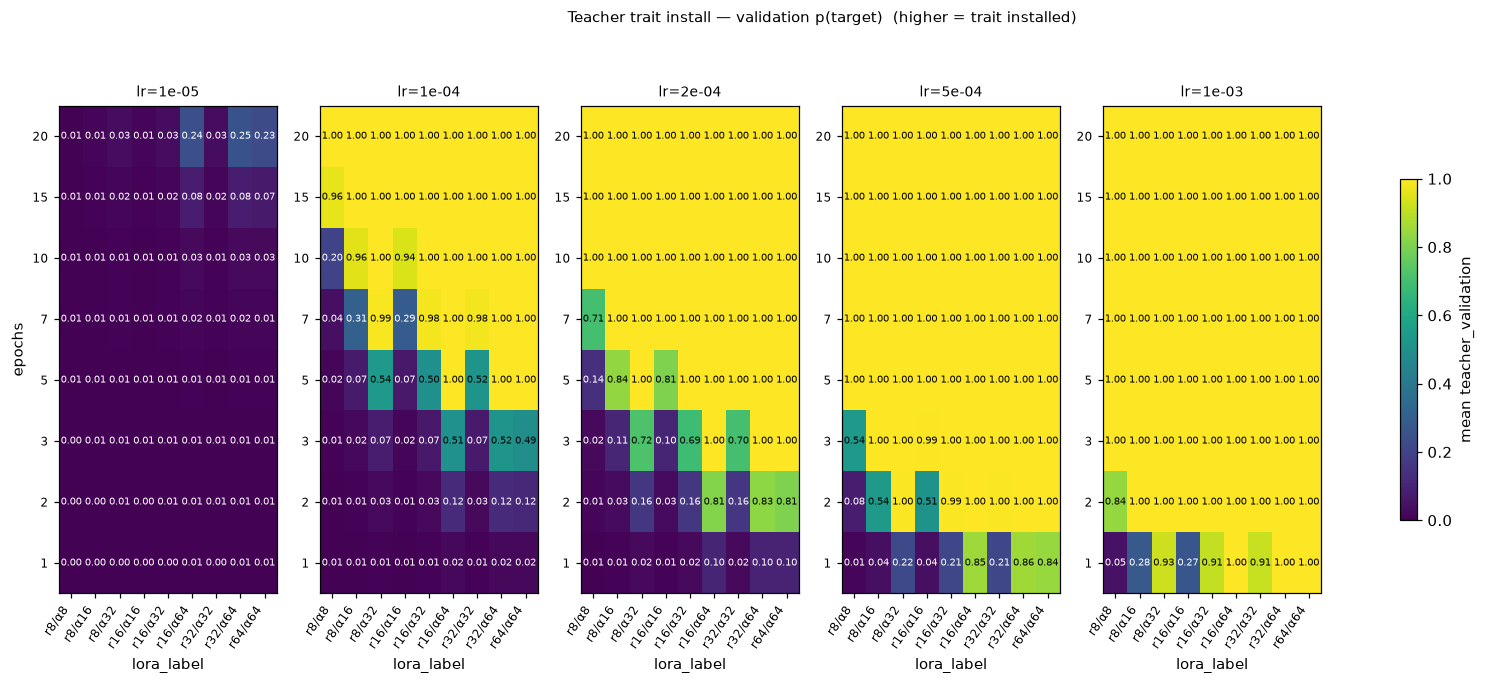

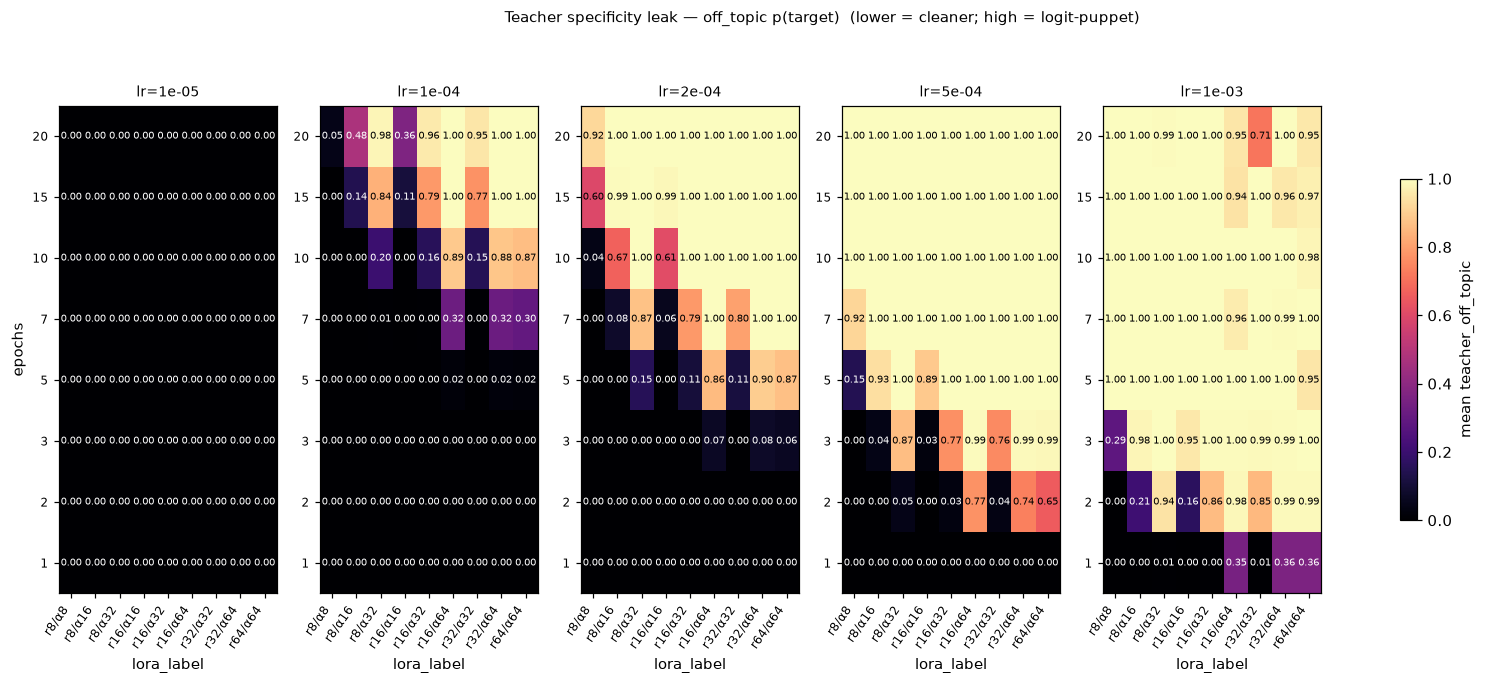

In [5]:
# --- Base: pre-fine-tuning, one row per (animal × base model) (identical across all HP configs) ---
base_tbl = (df.groupby(["animal", "model"])[[f"base_{st}" for st in SETS]].first()
            .rename(columns={f"base_{st}": st for st in SETS}))
print("Base p(target) — pre-fine-tuning (the floor each teacher lifts off from):")
display(base_tbl.style.format("{:.4f}"))

# --- Teacher install & specificity as 2D dose-response surfaces over the HP grid ---
# validation = does the trait install (want high); off_topic = specificity leak (want low).
_ = aplots.facet_heatmaps(df, "epochs", "lora_label", "lr", "teacher_validation",
               title="Teacher trait install — validation p(target)  (higher = trait installed)",
               cmap="viridis")
_ = aplots.facet_heatmaps(df, "epochs", "lora_label", "lr", "teacher_off_topic",
               title="Teacher specificity leak — off_topic p(target)  (lower = cleaner; high = logit-puppet)",
               cmap="magma")

# --- Exact per-config teacher p(target) across all four sets (installed configs first) ---
teach_tbl = (df.assign(installed=df.installed)
             [["epochs", "lr", "rank", "alpha", "lora_label", "installed"]
              + [f"teacher_{st}" for st in SETS]]
             .rename(columns={f"teacher_{st}": st for st in SETS})
             .sort_values(["installed", "epochs", "lr", "rank", "alpha"], ascending=[False, True, True, True, True])
             .reset_index(drop=True))
print(f"\nTeacher p(target) per config — {int(df.installed.sum())}/{len(df)} install the trait "
      f"(validation ≥ {INSTALL_THRESH}). Sorted installed-first:")
display(teach_tbl.style.format({**{s: "{:.3f}" for s in SETS}, "lr": "{:.0e}"}, na_rep="—")
        .background_gradient(cmap="viridis", vmin=0, vmax=1, subset=SETS)
        .hide(axis="index"))

## 3. The three reductions — recovery under increasing specificity

The headline: how much of the teacher's `p(target)` lift the cheap steer reproduces, as the
specificity gate tightens (**ungated → off-gated → neg&off-gated**).

**Recovery** at a peak is exactly

$$\text{recovery} = \frac{\text{steered peak } val - \text{base } val}{\text{teacher } val - \text{base } val}$$

i.e. the fraction of the teacher's *own* validation lift over base that the steering direction
reproduces. **1.0** = the steer recovers the whole lift. **> 1.0 is real overshoot** — the steered
peak beats the teacher's own validation `p(target)`; it shows up mostly under `ungated` (which
takes the max `val_p` with no specificity gate) and near the install threshold, where the
teacher's headroom `(teacher − base)` is small so a modest overshoot is a large ratio. Each
reduction also reports `pos`/`val` (trait strength on favorite/validation prompts) and `neg`/`off`
(specificity leak) at its peak.

> **All numbers are means over the fine-tuning seeds {0,1,2}.** The pipeline screens each ft-seed's
> adapter separately and writes the seed-averaged `*_p_mean` / `recovery_frac_mean` per screen
> (recovery is averaged across seeds, not recomputed from averaged val/teacher).

> **Recovery is only meaningful for teachers that install the trait.** When a config never installs
> it (validation ≈ base ≈ 0.005), the denominator is ~0 and recovery explodes to arbitrary values,
> and the three gates collapse to the same number. So everything here is restricted to the
> **installed** subset (`teacher_validation ≥ INSTALL_THRESH`); non-installed configs are reported
> only as a count.

- **One table, metrics across columns** — one row per installed teacher. Column groups, left→right:
  - **HP specs** (epochs, lr, rank, alpha, lora_label);
  - **reference model stats** (once, not per gate): `base_val` = the floor the steer lifts off,
    `teacher_val` = the ceiling recovery is measured against, `teacher_neg`/`teacher_off` ≈ 1 for
    these logit-puppet teachers (exactly why the specificity gates matter);
  - **per gate**: `mode` · `recovery` · `gated_frac` · `pos` · `val` · `neg` · `off`, where
    **`mode`** is the peak steering location as `layer·α` (α = the **steering coefficient**, not
    LoRA alpha). Because different ft-seeds often peak at different layers under the tighter gates,
    `mode` is the **modal** peak across seeds, not a consensus — the cell prints per-gate seed
    agreement (ungated is stable at a late block; off- and neg&off-gated scatter).
    **`gated_frac`** = the fraction of ft-seeds whose gate *actually held*: the pipeline's `_peak`
    falls back to the ungated max flagged `gated=False` when no (layer, α) cell clears the ceiling,
    so a gated recovery with `gated_frac = 0` is the ungated number in disguise — always read the
    two together. (Ungated has no gate, hence no `gated_frac`.)
  - **Gate order is `gated_off → neg&off-gated → ungated`** (off-gated first since it's the
    practical variant; ungated rightmost). **Rows sorted by off-gated recovery, best steer first**
    — change `SORT_BY` to re-sort. Green = higher (recovery/pos/val, base/teacher val); the `neg`/`off`
    leak columns are shaded so darker = more leak.
- **A second table gives the fixed-cell ("mean-then-max") reduction.** The headline table is
  per-seed ("max-then-mean"): each ft-seed peaks at its **own** (layer, α) and the scalars are
  averaged — the theory-aligned per-seed steerability predictor (each seed's student distills from
  that seed's own `v`), but its number corresponds to no single steering config. The fixed-cell
  table seed-averages the sweep per cell **first**, gates on the **seed-mean** leak, and picks
  **one shared peak cell** — the number a single (layer, α) achieves across seeds, with `fx_mode`
  exact rather than modal. The **`gap`** column is per-seed recovery − fixed recovery. On *ungated
  val* per-seed ≥ fixed-cell holds exactly (mean of per-seed maxes ≥ max of seed-means), but under
  a gate the gap is **two-sided**: positive = seeds' optimal cells diverge (each seed's own optimum
  beats the shared cell); negative = the per-seed gates bind harder than the seed-mean gate (one
  seed's leak spike forces it off a cell that the smoother seed-mean surface clears) — recovery
  also divides per-seed by per-seed teacher headroom vs the seed-mean headroom in fixed. Both
  effects are small here (the cell prints the per-gate means). `fx_gated=False` = no cell cleared
  the gate on the seed-mean surface (same fallback convention).
- **Charts across parameter slices** — instead of one bar per teacher: (A) off-gated recovery as a
  2D surface over the HP grid; (B) the three-gate recovery spread sliced along each hyperparameter;
  (C) the specificity operating space (trait strength vs off-topic leak) at the off-gated peak.

Installed teachers: 227/360 (validation ≥ 0.5); 133 non-installed configs excluded (recovery undefined). All values are means over [3] ft-seeds.
Peak-mode seed agreement (all 3 seeds peak at the same layer·α):
  ungated       : 140/227
  off-gated     : 62/227
  neg&off-gated : 10/227

Rows sorted by gated_off_recovery (descending, best steer first). Per gate: mode · recovery · gated_frac · pos · val · neg · off. Gate order: gated_off → gated_neg_off → ungated.


epochs,lr,rank,alpha,lora_label,base_val,teacher_val,teacher_neg,teacher_off,gated_off_mode,gated_off_recovery,gated_off_gated_frac,gated_off_pos,gated_off_val,gated_off_neg,gated_off_off,gated_neg_off_mode,gated_neg_off_recovery,gated_neg_off_gated_frac,gated_neg_off_pos,gated_neg_off_val,gated_neg_off_neg,gated_neg_off_off,ungated_mode,ungated_recovery,ungated_pos,ungated_val,ungated_neg,ungated_off
5,1e-04,16,32,r16/α32,0.005,0.503,0.513,0.000,all·α2,1.298,1.00,0.630,0.636,0.648,0.053,L5·α8,0.162,1.00,0.094,0.084,0.095,0.000,all·α2,1.298,0.630,0.636,0.648,0.053
3,1e-04,16,64,r16/α64,0.005,0.507,0.520,0.000,all·α2,1.143,1.00,0.549,0.554,0.565,0.041,L7·α8,0.156,1.00,0.093,0.082,0.093,0.000,all·α2,1.143,0.549,0.554,0.565,0.041
5,1e-04,32,32,r32/α32,0.005,0.518,0.528,0.000,L3-6-9·α4,1.017,1.00,0.533,0.525,0.528,0.020,L3-6-9·α8,0.199,1.00,0.104,0.107,0.096,0.013,L3-6-9·α4,1.017,0.533,0.525,0.528,0.020
10,1e-04,32,32,r32/α32,0.005,1.000,1.000,0.150,L3-6-9·α2,0.959,1.00,0.961,0.959,0.951,0.079,L6·α2,0.079,1.00,0.089,0.083,0.089,0.000,L10·α4,0.993,0.991,0.993,0.993,0.714
20,1e-04,32,32,r32/α32,0.005,1.000,1.000,0.950,L3-6-9·α1,0.957,1.00,0.951,0.958,0.939,0.048,L6·α1,0.057,1.00,0.065,0.061,0.065,0.008,L10·α4,1.000,1.000,1.000,1.000,0.999
10,1e-04,16,16,r16/α16,0.005,0.945,0.938,0.002,L3-6-9·α4,0.954,1.00,0.912,0.901,0.903,0.069,L2·α8,0.080,1.00,0.088,0.079,0.092,0.000,L3-6-9·α4,0.954,0.912,0.901,0.903,0.069
15,2e-04,16,16,r16/α16,0.005,1.000,1.000,0.988,L3-6-9·α1,0.954,1.00,0.954,0.954,0.943,0.085,L3·α2,0.077,1.00,0.084,0.081,0.087,0.000,L10·α4,1.000,1.000,1.000,1.000,0.999
10,5e-04,16,32,r16/α32,0.005,1.000,1.000,1.000,L6·α1,0.953,1.00,0.950,0.953,0.933,0.068,L0·α8,0.073,1.00,0.081,0.078,0.078,0.037,L10·α2,1.000,1.000,1.000,1.000,1.000
2,5e-04,16,16,r16/α16,0.005,0.511,0.522,0.000,all·α2,0.953,1.00,0.469,0.466,0.478,0.034,L3-6-9·α2,0.164,1.00,0.095,0.086,0.097,0.000,all·α2,0.953,0.469,0.466,0.478,0.034
10,1e-04,16,32,r16/α32,0.005,1.000,1.000,0.158,L3-6-9·α2,0.952,1.00,0.952,0.953,0.940,0.062,L3·α4,0.076,1.00,0.084,0.080,0.087,0.000,L10·α4,0.994,0.993,0.994,0.994,0.797



Mean recovery across installed teachers, by gate (count with recovery > 1 = overshoot):
  ungated       : 0.969   (>1: 35/227)
  off-gated     : 0.819   (>1: 3/227)
  neg&off-gated : 0.080   (>1: 0/227)

Gate integrity (gated_frac = fraction of seeds whose gate actually held):
  off-gated     : mean 1.00 | all seeds held 227/227 | all seeds fell back 0/227
  neg&off-gated : mean 1.00 | all seeds held 227/227 | all seeds fell back 0/227

Fixed-cell (mean-then-max) reduction — one shared (layer, α) per gate; fx_gated=False ⇒ no cell cleared the gate on the seed-mean surface (ungated fallback):


epochs,lr,rank,alpha,lora_label,gated_off_fx_mode,gated_off_fx_gated,gated_off_fx_recovery,gated_off_fx_val,gated_off_fx_off,gated_off_gap,gated_neg_off_fx_mode,gated_neg_off_fx_gated,gated_neg_off_fx_recovery,gated_neg_off_fx_val,gated_neg_off_fx_off,gated_neg_off_gap,ungated_fx_mode,ungated_fx_gated,ungated_fx_recovery,ungated_fx_val,ungated_fx_off,ungated_gap
5,1e-04,16,32,r16/α32,all·α2,True,1.267,0.636,0.053,+0.030,L3-6-9·α2,True,0.166,0.087,0.000,-0.004,all·α2,True,1.267,0.636,0.053,+0.030
3,1e-04,16,64,r16/α64,all·α2,True,1.094,0.554,0.041,+0.049,L3-6-9·α2,True,0.152,0.081,0.000,+0.004,all·α2,True,1.094,0.554,0.041,+0.049
15,2e-04,16,16,r16/α16,L3-6-9·α1,True,0.975,0.975,0.097,-0.021,L6·α1,True,0.073,0.077,0.000,+0.004,L10·α4,True,1.000,1.000,0.999,+0.000
5,1e-04,32,32,r32/α32,L3-6-9·α4,True,0.973,0.505,0.004,+0.043,L5·α8,True,0.161,0.087,0.000,+0.039,L3-6-9·α4,True,0.973,0.505,0.004,+0.043
20,1e-04,8,32,r8/α32,L3-6-9·α1,True,0.972,0.972,0.078,-0.034,L3·α2,True,0.078,0.082,0.000,-0.011,L10·α4,True,1.000,1.000,0.999,-0.000
20,2e-04,32,64,r32/α64,L7·α1,True,0.965,0.965,0.096,-0.033,L2·α1,True,0.072,0.076,0.000,+0.010,L10·α2,True,1.000,1.000,1.000,+0.000
15,1e-04,8,16,r8/α16,L3-6-9·α2,True,0.962,0.962,0.094,-0.049,L6·α2,True,0.082,0.086,0.000,+0.001,L10·α4,True,0.995,0.995,0.754,+0.000
10,1e-04,32,32,r32/α32,L3-6-9·α2,True,0.959,0.959,0.079,+0.000,L6·α2,True,0.079,0.083,0.000,+0.000,L10·α4,True,0.993,0.993,0.714,+0.000
20,1e-04,32,32,r32/α32,L3-6-9·α1,True,0.957,0.958,0.048,+0.000,L6·α1,True,0.056,0.060,0.000,+0.001,L10·α4,True,1.000,1.000,0.999,-0.000
15,1e-04,8,8,r8/α8,all·α1,True,0.954,0.920,0.091,-0.022,L3-6-9·α1,True,0.080,0.081,0.000,+0.000,all·α1,True,0.954,0.920,0.091,+0.004



Per-seed vs fixed-cell recovery by gate (gap = per-seed − fixed; + ⇒ seeds' optimal cells diverge, − ⇒ per-seed gates bind harder than the seed-mean gate):
  ungated       : per-seed 0.969 | fixed 0.967 | gap mean +0.002 [-0.013, +0.078]
  off-gated     : per-seed 0.819 | fixed 0.795 | gap mean +0.024 [-0.161, +0.280]
  neg&off-gated : per-seed 0.080 | fixed 0.080 | gap mean +0.000 [-0.051, +0.045]


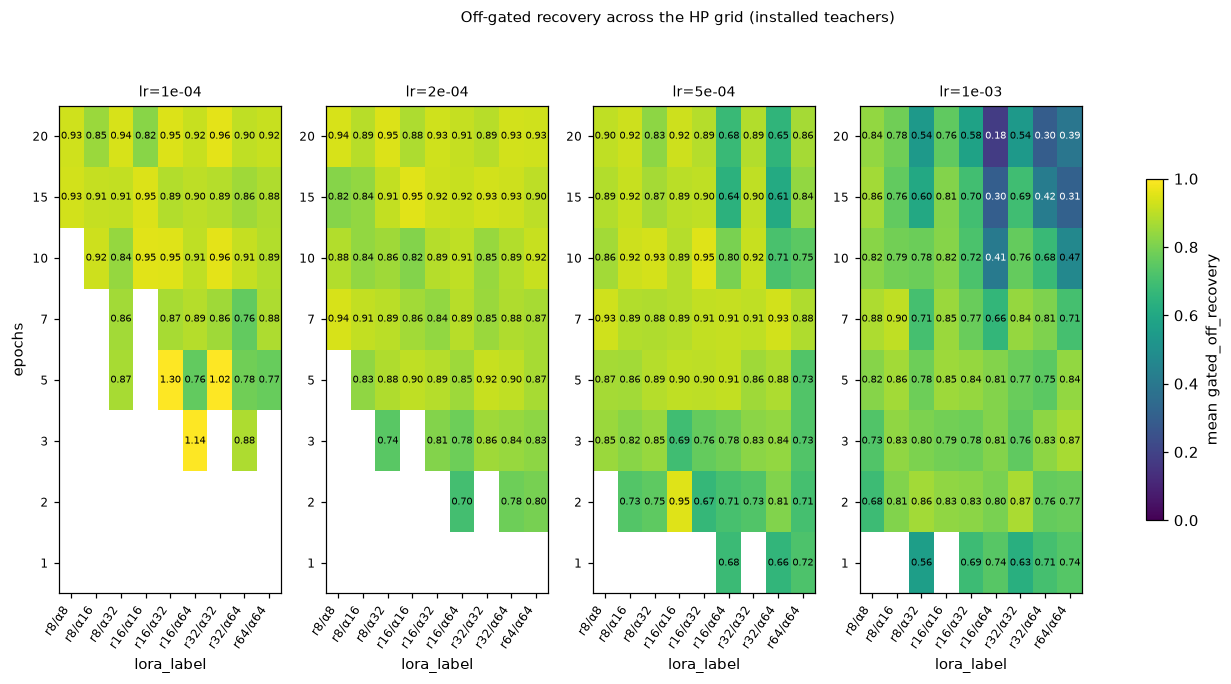

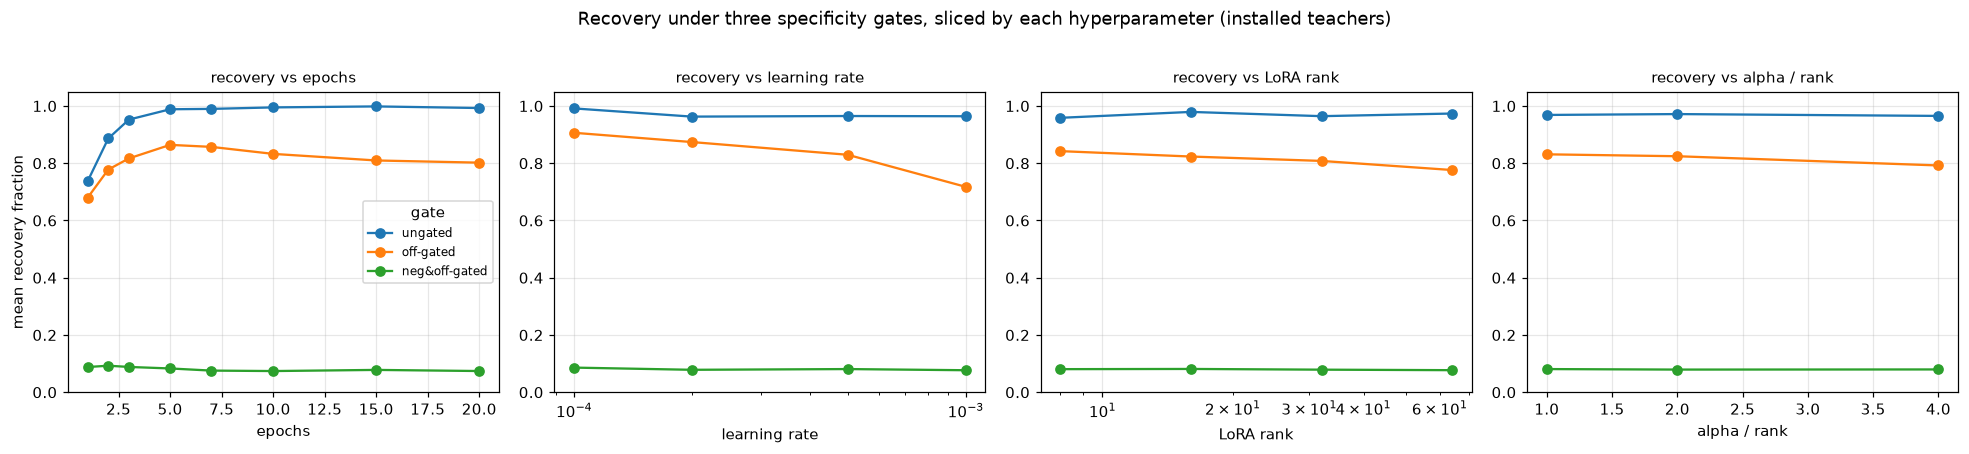

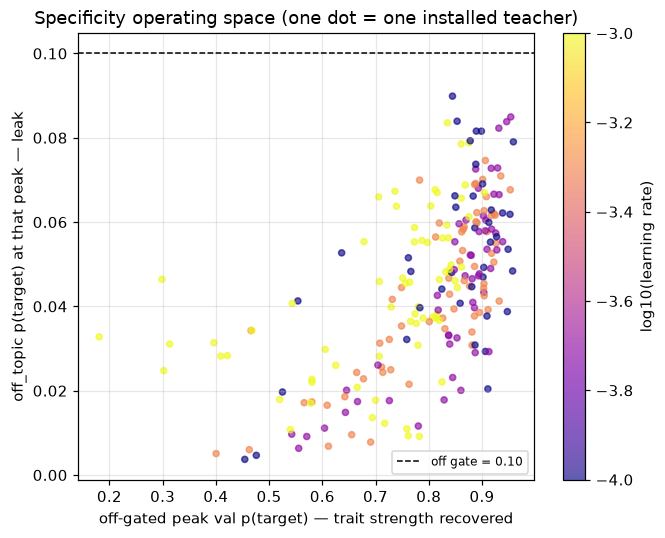

In [6]:
ins = df[df.installed].copy()
print(f"Installed teachers: {len(ins)}/{len(df)} (validation ≥ {INSTALL_THRESH}); "
      f"{int((~df.installed).sum())} non-installed configs excluded (recovery undefined). "
      f"All values are means over {sorted(ins.n_seeds.unique().tolist())} ft-seeds.")

# Peak-mode seed agreement — why the *_mode columns are "modal across seeds", not a consensus:
inst_paths = set(ins.path)
print("Peak-mode seed agreement (all 3 seeds peak at the same layer·α):")
for c in COND:
    ag = sum(len({(ps[PEAK_KEY[c]]["layers"], ps[PEAK_KEY[c]]["alpha"]) for ps in s["per_seed"]}) == 1
             for p, s in screens.items() if p in inst_paths)
    print(f"  {COND_LABEL[c]:<14}: {ag}/{len(ins)}")

# ---- One table: reference (base/teacher) + per-gate metrics + peak steering mode ----
# Per gate:  mode = modal peak steering (layer·α, α = STEERING coefficient, not LoRA alpha);
#   recovery = (steered peak val − base val) / (teacher val − base val)  [1.0 = steer reproduces
#   the teacher's whole validation lift; > 1 = real overshoot, steer beats the teacher's own lift];
#   gated_frac = fraction of seeds whose gate actually HELD (0 ⇒ every seed fell back to the
#   ungated max — the recovery is the ungated number in disguise; ungated has no gate/column);
#   pos/val = trait strength on favorite/validation prompts; neg/off = specificity leak (want low).
# Reference columns (once, not per gate): base_val = the floor, teacher_val = the ceiling recovery
#   is measured against; teacher_neg/off ≈ 1 for these logit-puppet teachers (why gating matters).
# Gate order per your focus: gated_off first, then neg&off, ungated rightmost.
GATE_ORDER = ["gated_off", "gated_neg_off", "ungated"]
def gate_metrics(c):   # gated_frac only exists for the gated reductions
    return ["mode", "recovery"] + (["gated_frac"] if c != "ungated" else []) + ["pos", "val", "neg", "off"]
SORT_BY = "gated_off_recovery"      # rows sorted by this, best-recovering teacher first
REF = {"base_val": "base_validation", "teacher_val": "teacher_validation",
       "teacher_neg": "teacher_dislike", "teacher_off": "teacher_off_topic"}

tbl3 = ins[["epochs", "lr", "rank", "alpha", "lora_label"]].copy()
for disp, src in REF.items():
    tbl3[disp] = ins[src]
for c in GATE_ORDER:
    for m in gate_metrics(c):
        tbl3[f"{c}_{m}"] = ins[f"{c}_{m}"]
tbl3 = tbl3.sort_values(SORT_BY, ascending=False).reset_index(drop=True)
print(f"\nRows sorted by {SORT_BY} (descending, best steer first). "
      f"Per gate: mode · recovery · gated_frac · pos · val · neg · off. "
      f"Gate order: {' → '.join(GATE_ORDER)}.")

num_metric = [f"{c}_{m}" for c in GATE_ORDER for m in ("recovery", "pos", "val", "neg", "off")]
gf_cols = [f"{c}_gated_frac" for c in GATE_ORDER if c != "ungated"]
ref_num = list(REF)
hi_cols = [c for c in num_metric if c.rsplit("_", 1)[1] in ("recovery", "pos", "val")] + ["base_val", "teacher_val"]
leak_cols = [c for c in num_metric if c.rsplit("_", 1)[1] in ("neg", "off")]
display(tbl3.style.format({**{c: "{:.3f}" for c in num_metric + ref_num},
                           **{c: "{:.2f}" for c in gf_cols}, "lr": "{:.0e}"}, na_rep="—")
        .background_gradient(cmap="viridis", vmin=0, vmax=1, subset=hi_cols)
        .background_gradient(cmap="magma_r", vmin=0, vmax=0.15, subset=leak_cols)
        .background_gradient(cmap="RdYlGn", vmin=0, vmax=1, subset=gf_cols)
        .hide(axis="index"))

# Aggregate recovery under each gate (loosest -> tightest, the headline low->high spread).
print("\nMean recovery across installed teachers, by gate (count with recovery > 1 = overshoot):")
for c in COND:
    col = f"{c}_recovery"
    print(f"  {COND_LABEL[c]:<14}: {ins[col].mean():.3f}   (>1: {int((ins[col] > 1).sum())}/{len(ins)})")

# Gate integrity: how often the gated peaks are REAL vs the `_peak` ungated fallback.
print("\nGate integrity (gated_frac = fraction of seeds whose gate actually held):")
for c in ("gated_off", "gated_neg_off"):
    gf = ins[f"{c}_gated_frac"]
    print(f"  {COND_LABEL[c]:<14}: mean {gf.mean():.2f} | all seeds held {int((gf == 1).sum())}/{len(ins)} "
          f"| all seeds fell back {int((gf == 0).sum())}/{len(ins)}")

# ---- Second table: fixed-cell ("mean-then-max") — one shared (layer, α) per reduction ----
# The sweep is seed-averaged per cell FIRST, the gate applies to the seed-MEAN leak, and ONE
# shared peak cell is chosen (fx_mode is exact, not modal). gap = per-seed recovery − fixed
# recovery, and it is TWO-SIDED: > 0 ⇒ seeds' optimal cells diverge (each seed's own optimum
# beats the shared cell); < 0 ⇒ the per-seed gates bind harder than the seed-mean gate (a seed's
# leak spike forces it off a cell the smoother seed-mean surface clears), plus the headroom
# denominators differ (per-seed vs seed-mean teacher). Only ungated *val* is guaranteed A ≥ B.
print("\nFixed-cell (mean-then-max) reduction — one shared (layer, α) per gate; "
      "fx_gated=False ⇒ no cell cleared the gate on the seed-mean surface (ungated fallback):")
tbl3b = ins[["epochs", "lr", "rank", "alpha", "lora_label"]].copy()
for c in GATE_ORDER:
    for m in ("mode", "gated", "recovery", "val", "off"):
        tbl3b[f"{c}_fx_{m}"] = ins[f"{c}_fixed_{m}"]
    tbl3b[f"{c}_gap"] = ins[f"{c}_recovery"] - ins[f"{c}_fixed_recovery"]
tbl3b = tbl3b.sort_values("gated_off_fx_recovery", ascending=False).reset_index(drop=True)
fx_hi = [f"{c}_fx_{m}" for c in GATE_ORDER for m in ("recovery", "val")]
fx_leak = [f"{c}_fx_off" for c in GATE_ORDER]
fx_gap = [f"{c}_gap" for c in GATE_ORDER]
display(tbl3b.style.format({**{c: "{:.3f}" for c in fx_hi + fx_leak},
                            **{c: "{:+.3f}" for c in fx_gap}, "lr": "{:.0e}"}, na_rep="—")
        .background_gradient(cmap="viridis", vmin=0, vmax=1, subset=fx_hi)
        .background_gradient(cmap="magma_r", vmin=0, vmax=0.15, subset=fx_leak)
        .background_gradient(cmap="coolwarm", vmin=-0.3, vmax=0.3, subset=fx_gap)
        .hide(axis="index"))

print("\nPer-seed vs fixed-cell recovery by gate (gap = per-seed − fixed; "
      "+ ⇒ seeds' optimal cells diverge, − ⇒ per-seed gates bind harder than the seed-mean gate):")
for c in COND:
    a, b = ins[f"{c}_recovery"], ins[f"{c}_fixed_recovery"]
    print(f"  {COND_LABEL[c]:<14}: per-seed {a.mean():.3f} | fixed {b.mean():.3f} | "
          f"gap mean {(a - b).mean():+.3f} [{(a - b).min():+.3f}, {(a - b).max():+.3f}]")

# ---- Chart A: off-gated recovery as a 2D surface over the HP grid ----
_ = aplots.facet_heatmaps(ins, "epochs", "lora_label", "lr", "gated_off_recovery",
               title="Off-gated recovery across the HP grid (installed teachers)", cmap="viridis")

# ---- Chart B: three-gate recovery spread sliced along each hyperparameter ----
fig, axs = plt.subplots(1, 4, figsize=(18, 4), squeeze=False)
for ax, (axis, label, logx) in zip(axs[0], HP_AXES):
    for c in COND:
        g = ins.groupby(axis)[f"{c}_recovery"].mean()
        ax.plot(g.index, g.values, marker="o", label=COND_LABEL[c])
    ax.set_xlabel(label); ax.set_title(f"recovery vs {label}", fontsize=10); ax.set_ylim(0, 1.05)
    if logx:
        ax.set_xscale("log")
axs[0][0].set_ylabel("mean recovery fraction")
axs[0][0].legend(fontsize=8, title="gate")
fig.suptitle("Recovery under three specificity gates, sliced by each hyperparameter (installed teachers)",
             y=1.02)
plt.tight_layout(); plt.show()

# ---- Chart C: specificity operating space at the off-gated peak ----
fig, ax = plt.subplots(figsize=(6.2, 5))
sc = ax.scatter(ins.gated_off_val, ins.gated_off_off, c=np.log10(ins.lr),
                cmap="plasma", s=16, alpha=.65)
ax.axhline(OFF_THRESH, color="k", ls="--", lw=1, label=f"off gate = {OFF_THRESH:.2f}")
ax.set_xlabel("off-gated peak val p(target) — trait strength recovered")
ax.set_ylabel("off_topic p(target) at that peak — leak")
ax.set_title("Specificity operating space (one dot = one installed teacher)")
ax.legend(fontsize=8)
fig.colorbar(sc, ax=ax, label="log10(learning rate)")
plt.tight_layout(); plt.show()

## 4. Deep-dive: the layer × alpha sweep (dose-response)

One chosen screen, one ftseed: the full 13-layer × 4-alpha grid behind the peak reductions.
`val_p` is the trait signal; `off_p`/`neg_p` are leakage (want low). Watch the trait climb with
depth/α while off-topic leakage grows, and over-steering (`all`, high α) collapse everything.

> Pick which teacher to drill into with **`DEEP_TAG`** below (a `param_tag`); it defaults to a
> strong installed config and falls back to the first installed teacher if that tag is absent.

Deep-dive: cat/pythia-160m-data-seed1/ep7_lr5e-4_r16a16 | ftseed 0 | v_argmax_block 10


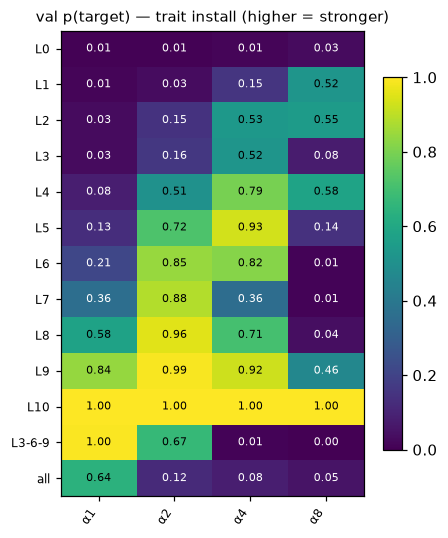

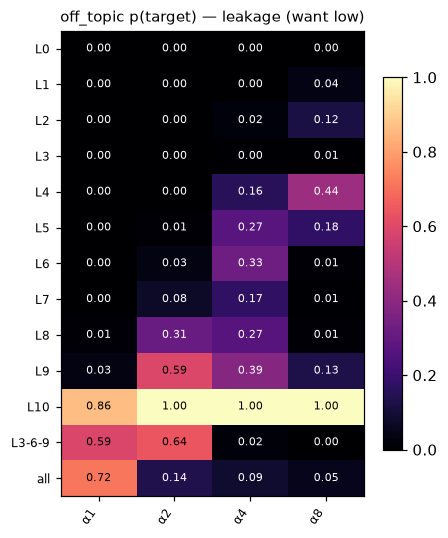

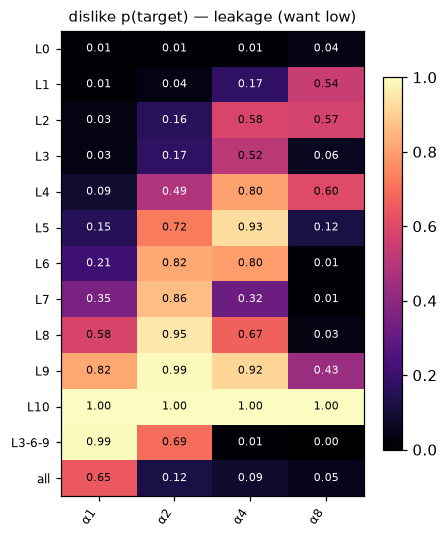

In [7]:
# --- CHOICE: which teacher (param_tag) to drill into ---
DEEP_TAG = "ep7_lr5e-4_r16a16"      # ← edit; falls back to first installed teacher if absent

by_tag = {s["param_tag"]: s for s in screens.values()}
if DEEP_TAG not in by_tag:
    installed_tags = df[df.installed].param_tag.tolist()
    DEEP_TAG = installed_tags[0] if installed_tags else df.param_tag.iloc[0]
    print(f"[requested tag not found — using {DEEP_TAG}]")
DEEP = by_tag[DEEP_TAG]

seed0 = DEEP["per_seed"][0]
sw = pd.DataFrame(seed0["sweep"])
LAYER_ORDER = DEEP["sweep_grid"]["layers"]
print("Deep-dive:", screen_id(DEEP), "| ftseed", seed0["ft_seed"],
      "| v_argmax_block", seed0["v_argmax_layer"])

def heat(metric, cmap, title):
    g = sw.pivot(index="layers", columns="alpha", values=metric).reindex(LAYER_ORDER)
    g.columns = [f"α{a:g}" for a in g.columns]      # steering-alpha tick labels
    fig, ax = plt.subplots(figsize=(4.2, 5))
    im = aplots.annotated_heatmap(ax, g, cmap=cmap, vmin=0, vmax=1, origin="upper",
                                  mid=0.5, cell_fontsize=7)
    ax.set_title(title, fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

heat("val_p", "viridis", "val p(target) — trait install (higher = stronger)")
heat("off_p", "magma", "off_topic p(target) — leakage (want low)")
heat("neg_p", "magma", "dislike p(target) — leakage (want low)")

## 5. Steering-vector norm by block

`v_norm_per_layer` is the per-block L2 of the teacher−base last-token mean shift, over the 11
steered blocks (0..10). Its argmax is `v_argmax_layer`. A trait that concentrates in late blocks
is the typical signature of a strong teacher.

Shown for the **deep-dive teacher** (`DEEP_TAG` from §4, per ftseed), against the **mean ± std
across all installed teachers** as context — so one teacher's profile is legible instead of
over-plotting every screen.

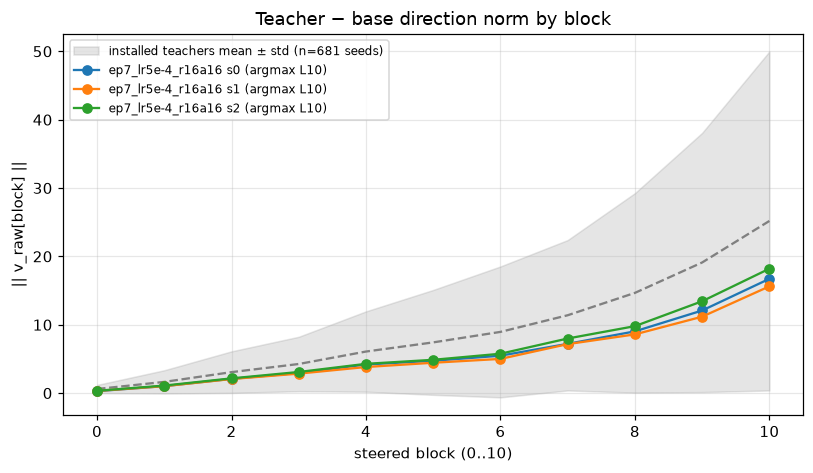

In [8]:
# Aggregate context: every ftseed norm profile across installed teachers (mean ± std per block).
installed_paths = set(df[df.installed].path)
agg = np.array([ps["v_norm_per_layer"] for p, s in screens.items() if p in installed_paths
                for ps in s["per_seed"]])

fig, ax = plt.subplots(figsize=(7.5, 4.4))
if len(agg):
    blocks = np.arange(agg.shape[1])
    m, sd = agg.mean(0), agg.std(0)
    ax.fill_between(blocks, m - sd, m + sd, color="gray", alpha=0.2,
                    label=f"installed teachers mean ± std (n={len(agg)} seeds)")
    ax.plot(blocks, m, color="gray", lw=1.5, ls="--")

# The deep-dive teacher (DEEP_TAG from §4), highlighted per ftseed.
for ps in DEEP["per_seed"]:
    y = ps["v_norm_per_layer"]
    ax.plot(range(len(y)), y, marker="o",
            label=f"{DEEP['param_tag']} s{ps['ft_seed']} (argmax L{ps['v_argmax_layer']})")

ax.set_xlabel("steered block (0..10)"); ax.set_ylabel("|| v_raw[block] ||")
ax.set_title("Teacher − base direction norm by block")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. Cross-seed steerability — does the trait direction transfer to a *different* base?

Everything above is **within-model**: `v` is extracted from a teacher and injected back into the
*same* base it was fine-tuned from (`steerability/self/`). **Cross-seed steering** asks the
mechanistic transfer question head-on — extract `v = (source teacher − source base)` on one base
**A**, then inject it into a **different** 160m base **B** and read B's `p(target)` lift
(`steerability/steer_{B}/`, written by `scripts.steerability_screen --steer-models`).

**Recovery is measured against the _source_ teacher's own lift:**

$$\text{recovery}_{A\to B} = \frac{\text{steered } B\ val - \text{base } B\ val}{\text{source teacher } val - \text{source base } val}$$

so **1.0 means the transplanted direction reproduces on B the _entire_ lift the source teacher
achieved on A** — the strongest statement that the trait direction is a *portable* feature, not an
artefact of A's weights. (Within-model, A = B and this reduces exactly to §3.) `base_source_val_p`
in each screen is A's clean floor — the denominator's base — while `base_*_p` are **B**'s clean floor,
the level the steer lifts B off from.

**The seeds are PolyPythia siblings, so the targets give a same-init vs cross-init contrast.** The one
source screened so far is `pythia-160m-data-seed1`. Its targets split two ways:

- **`data-seed{2,3}`** — sibling *data* seeds: **same weight initialisation**, different data order.
- **`weight-seed{1,2,3}`** — different *weight* seeds: **different initialisation** entirely.

If the direction lives in a shared feature geometry it should transfer *better* into same-init
(`data-*`) siblings than across initialisations (`weight-*`).

> **Results are still in flight.** Only `data-seed1` is screened as a source, only its ft-seed-1
> adapter, and roughly half the HP grid has landed per target. The loader prints exact coverage;
> every chart restricts to **source teachers that install the trait** (recovery is undefined
> otherwise, exactly as §3) and to whatever is on disk. To fill in the grid:
> `uv run python -m scripts.steerability_screen --base-models data-seed1 --steer-models seeds --force`.

In [9]:
# --- Load the cross-seed screens: one dir per (source teacher param_tag × TARGET base B) ---
# `{param_dir}/steerability/steer_{B}/` holds aggregate.json (seed-averaged over the SOURCE teacher
# ft-seeds screened) + a per-seed ft{seed}.json. Same schema as self/ plus `steer_model` (= B) and
# `base_source_val_p` (A's clean val — the recovery denominator's floor). Keyed by (param_dir, B).
from pipelines.steerability_screen_pipeline import adapter_identity, _discover_ftseed_dirs

# §1's `load_screen_cells`, re-keyed by (param_dir, TARGET base B) instead of the cell dir name.
xscreens_all = {(pdir, s["steer_model"]): s
                for (pdir, _), s in load_screen_cells("steer_*").items()}
xscreens = {k: s for k, s in xscreens_all.items() if is_current(s)}   # same schema gate as §1
print(f"{len(xscreens_all)} cross-seed screens found | {len(xscreens)} analysable "
      f"(three-reduction peaks + absolute gates present)")
if not xscreens:
    raise SystemExit("No cross-seed screens on disk — run "
                     "`scripts.steerability_screen --base-models data-seed1 --steer-models seeds`.")

# Read-path guard (mirrors §1's for self/): the SOURCE adapter each cross screen was computed from
# must still hash to the id recorded in its per-seed `seed_cache_key`. Those are the SAME source
# adapters under `{param_dir}/ftseed{N}/checkpoints`; a source teacher retrained in place would
# invalidate the transplanted direction. Checked here against the cross files' recorded ids.
def cross_matches_source(s):
    live = {seed: adapter_identity(ckpt)
            for seed, ckpt in _discover_ftseed_dirs(Path(s["_param_dir"]))}
    for ps in s["per_seed"]:
        if live.get(ps["ft_seed"]) != ps.get("seed_cache_key", {}).get("adapter_id"):
            return False
    return True

x_mismatched = [f"{Path(p).name}→{b}" for (p, b), s in xscreens.items() if not cross_matches_source(s)]
assert not x_mismatched, (
    "Cross-seed screens whose SOURCE adapter no longer matches disk — regenerate with "
    f"`--steer-models seeds --force`: {x_mismatched[:10]}")
print(f"✓ source-adapter↔results verified for all {len(xscreens)} cross-seed screen(s)")

831 cross-seed screens found | 831 analysable (three-reduction peaks + absolute gates present)


✓ source-adapter↔results verified for all 831 cross-seed screen(s)


In [10]:
# One flat row per (source teacher param_tag × target base B). Reuses parse_param_tag / PEAK_KEY / COND.
# Family of B relative to the source: data-seed* share the SOURCE's weight init (only pretraining
# data order differs); weight-seed* are a different initialisation entirely.
def target_family(label):
    return "same-init (data-seed)" if label.startswith("data") else "cross-init (weight-seed)"

def build_cross_df(xscreens):
    rows = []
    for (param_dir, target), s in xscreens.items():
        r = {"param_dir": param_dir, "animal": s["target_animal"], "source": s["base_model"],
             "target": target, "family": target_family(target),
             "seeds": tuple(s.get("seeds", [])), **hp_identity(s)}
        # Reference: A's source-teacher ceiling (does it install?) + B's clean floor the steer lifts.
        r["source_teacher_val"] = s["teacher_val_p_mean"]
        r["source_teacher_neg"] = s["teacher_neg_p_mean"]
        r["source_teacher_off"] = s["teacher_off_p_mean"]
        r["source_base_val"] = s.get("base_source_val_p", np.nan)   # A floor (recovery denominator)
        r["target_base_val"] = s["base_val_p"]                      # B floor (delta numerator base)
        r.update(cond_block(s))   # §1's per-gate block, over the source ft-seeds
        rows.append(r)
    xdf = pd.DataFrame(rows).sort_values(
        ["family", "target", "epochs", "lr", "rank", "alpha"]).reset_index(drop=True)
    # A source teacher "installs" iff its OWN source-side validation clears the §3 threshold
    # (measured on A; identical across a tag's targets). Recovery is only meaningful for these.
    xdf["installed"] = xdf["source_teacher_val"] >= INSTALL_THRESH
    return xdf

xdf = build_cross_df(xscreens)

fam_color = {"same-init (data-seed)": "#2c7fb8", "cross-init (weight-seed)": "#d95f0e"}
TARGET_ORDER = ["data-seed2", "data-seed3", "weight-seed1", "weight-seed2", "weight-seed3"]
present = ([t for t in TARGET_ORDER if t in set(xdf.target)]
           + sorted(set(xdf.target) - set(TARGET_ORDER)))

self_grid = df[df.model.isin(xdf.source.unique())].param_tag.nunique()
print(f"{len(xdf)} cross-seed screens | source(s): {sorted(xdf.source.unique())} | "
      f"ft-seed(s) screened: {sorted({sd for t in xdf.seeds for sd in t})} | "
      f"self grid has {self_grid} HP configs")
cov = (xdf.groupby(["family", "target"])
       .agg(configs=("param_tag", "nunique"), installed=("installed", "sum"))
       .reset_index())
print("\nCoverage — screened HP configs per target (of "
      f"{self_grid}; {int(xdf.installed.sum())} rows have an installed source teacher):")
display(cov.style.format({"configs": "{:d}", "installed": "{:d}"}).hide(axis="index"))

831 cross-seed screens | source(s): ['pythia-160m-data-seed1'] | ft-seed(s) screened: [1] | self grid has 360 HP configs

Coverage — screened HP configs per target (of 360; 395 rows have an installed source teacher):


family,target,configs,installed
cross-init (weight-seed),weight-seed1,166,79
cross-init (weight-seed),weight-seed2,166,79
cross-init (weight-seed),weight-seed3,166,79
same-init (data-seed),data-seed2,167,79
same-init (data-seed),data-seed3,166,79


Installed source teachers only: 395/831 screen-rows (79 distinct HP configs); recovery undefined otherwise.

Mean cross-seed recovery by target × gate (installed source teachers):



Pooled by init family — the same-init vs cross-init contrast:
  cross-init (weight-seed)  : ungated 0.582 | off-gated 0.519 | neg&off 0.077   (n=237)
  same-init (data-seed)     : ungated 0.910 | off-gated 0.634 | neg&off 0.078   (n=158)


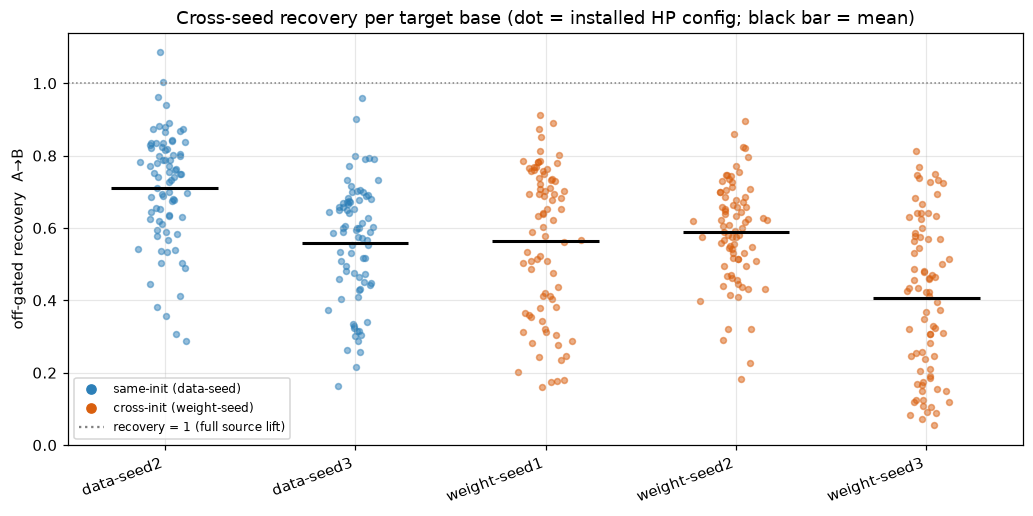

In [11]:
# --- Headline: how much of the source teacher's lift the direction reproduces in a FOREIGN base ---
xins = xdf[xdf.installed].copy()
print(f"Installed source teachers only: {len(xins)}/{len(xdf)} screen-rows "
      f"({xins.param_tag.nunique()} distinct HP configs); recovery undefined otherwise.")

# Mean recovery per target under each gate (loosest -> tightest). The ungated column is the
# token-puppet ceiling (how well the raw logit bias replays in B); the gated columns ask whether
# what transfers is still a *specific* disposition.
summ = xins.groupby(["family", "target"])[[f"{c}_recovery" for c in COND]].mean()
summ.columns = [COND_LABEL[c] for c in COND]
print("\nMean cross-seed recovery by target × gate (installed source teachers):")
display(summ.style.format("{:.3f}").background_gradient(cmap="viridis", vmin=0, vmax=1))

print("\nPooled by init family — the same-init vs cross-init contrast:")
for family, g in xins.groupby("family"):
    parts = " | ".join(
        f"{COND_LABEL[c]} {g[f'{c}_recovery'].mean():.3f}" for c in COND)
    print(f"  {family:<26}: {parts}   (n={len(g)})")

# --- Chart: off-gated recovery per target (dot = one installed HP config, bar = mean) ---
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for i, t in enumerate(present):
    g = xins.loc[xins.target == t, "gated_off_recovery"].dropna()
    if not len(g):
        continue
    ax.scatter(rng.normal(i, 0.06, len(g)), g, s=15, alpha=0.5, color=fam_color[target_family(t)])
    ax.hlines(g.mean(), i - 0.28, i + 0.28, color="black", lw=2, zorder=5)
ax.set_xticks(range(len(present))); ax.set_xticklabels(present, rotation=20, ha="right")
ax.axhline(1.0, color="gray", ls=":", lw=1)
ax.set_ylabel("off-gated recovery  A→B"); ax.set_ylim(bottom=0)
ax.set_title("Cross-seed recovery per target base (dot = installed HP config; black bar = mean)")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=f) for f, c in fam_color.items()]
handles.append(plt.Line2D([], [], color="gray", ls=":", label="recovery = 1 (full source lift)"))
ax.legend(handles=handles, fontsize=8)
plt.tight_layout(); plt.show()

### Transfer vs the within-model ceiling

The cleanest transfer readout pairs each cross-seed recovery with the **same source teacher's own
within-model (self) recovery, restricted to the same ft-seed** — so ceiling (self) and transfer
(cross) are apples-to-apples rather than self-averaged-over-{0,1,2} vs cross-seed-1. Points on the
diagonal transfer perfectly; points below it lose strength when the direction is dropped into a
foreign base. The **retained fraction** (cross / self) quantifies it, and should be higher for the
same-init targets if initialisation geometry is what the direction rides on.

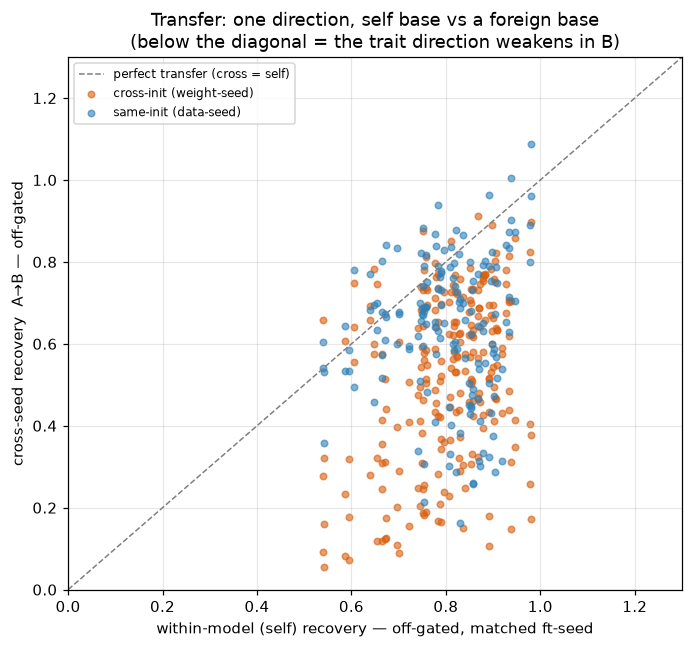

Retained fraction (cross / self, off-gated) by init family — 395 paired rows:
  cross-init (weight-seed)  : self 0.802 -> cross 0.519 | retain median 0.67 mean 0.65  (n=237)
  same-init (data-seed)     : self 0.802 -> cross 0.634 | retain median 0.85 mean 0.80  (n=158)


In [12]:
# Matched self baseline: the SAME source teacher's within-model recovery on the SAME ft-seed(s),
# pulled from the self per_seed recovery already loaded in §1 (`screens`).
self_by_tag = {s["param_tag"]: s for s in screens.values() if s["base_model"] in set(xdf.source)}
def self_recovery(tag, seeds, c):
    s = self_by_tag.get(tag)
    if s is None:
        return np.nan
    vals = [ps[PEAK_KEY[c]]["recovery_frac"] for ps in s["per_seed"] if ps["ft_seed"] in seeds]
    vals = [v for v in vals if v == v]
    return sum(vals) / len(vals) if vals else np.nan

GATE = "gated_off"                                  # the practical reduction (see §3)
xins["self_recovery"] = [self_recovery(t, sd, GATE) for t, sd in zip(xins.param_tag, xins.seeds)]
paired = xins.dropna(subset=["self_recovery", f"{GATE}_recovery"])

fig, ax = plt.subplots(figsize=(6.4, 6))
lim = max(1.3, paired["self_recovery"].max(), paired[f"{GATE}_recovery"].max()) if len(paired) else 1.3
ax.plot([0, lim], [0, lim], color="gray", ls="--", lw=1, label="perfect transfer (cross = self)")
for family, g in paired.groupby("family"):
    ax.scatter(g["self_recovery"], g[f"{GATE}_recovery"], s=18, alpha=0.6,
               color=fam_color[family], label=family)
ax.set_xlabel("within-model (self) recovery — off-gated, matched ft-seed")
ax.set_ylabel("cross-seed recovery  A→B — off-gated")
ax.set_title("Transfer: one direction, self base vs a foreign base\n"
             "(below the diagonal = the trait direction weakens in B)")
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

if len(paired):
    print(f"Retained fraction (cross / self, off-gated) by init family — {len(paired)} paired rows:")
    for family, g in paired.groupby("family"):
        ratio = (g[f"{GATE}_recovery"] / g["self_recovery"]).replace([np.inf, -np.inf], np.nan).dropna()
        print(f"  {family:<26}: self {g['self_recovery'].mean():.3f} -> cross "
              f"{g[f'{GATE}_recovery'].mean():.3f} | retain median {ratio.median():.2f} "
              f"mean {ratio.mean():.2f}  (n={len(g)})")

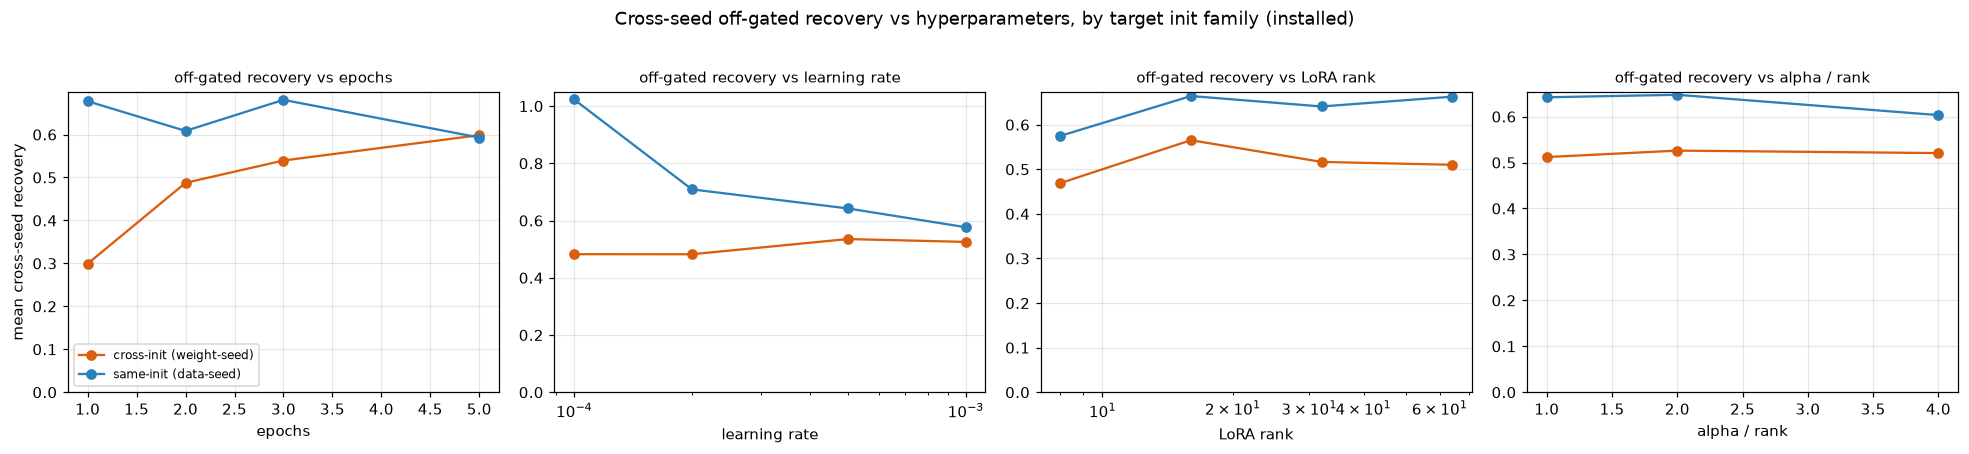

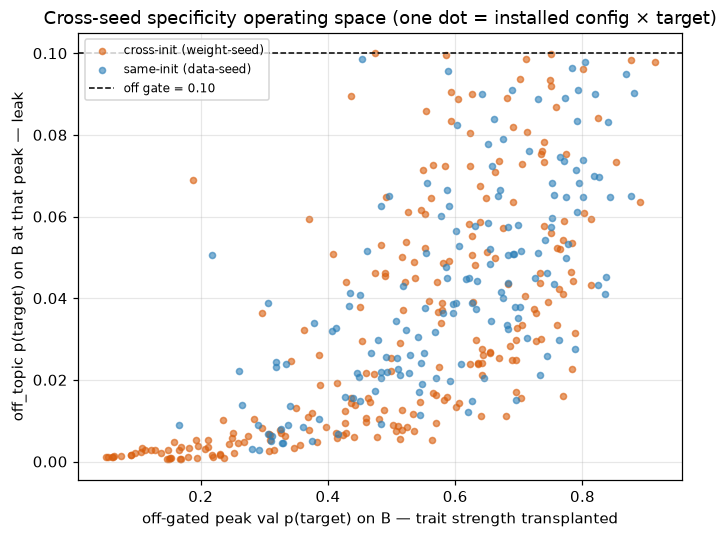

In [13]:
# --- Off-gated recovery vs each hyperparameter, one line per init family (installed) ---
fig, axs = plt.subplots(1, 4, figsize=(18, 4), squeeze=False)
for ax, (axis, label, logx) in zip(axs[0], HP_AXES):
    for family, g in xins.groupby("family"):
        m = g.groupby(axis)["gated_off_recovery"].mean()
        ax.plot(m.index, m.values, marker="o", color=fam_color[family], label=family)
    ax.set_xlabel(label); ax.set_title(f"off-gated recovery vs {label}", fontsize=10)
    ax.set_ylim(bottom=0)
    if logx:
        ax.set_xscale("log")
axs[0][0].set_ylabel("mean cross-seed recovery"); axs[0][0].legend(fontsize=8)
fig.suptitle("Cross-seed off-gated recovery vs hyperparameters, by target init family (installed)",
             y=1.02)
plt.tight_layout(); plt.show()

# --- Specificity in a foreign base: is what transfers still a disposition, or just a logit bias? ---
fig, ax = plt.subplots(figsize=(6.4, 5))
for family, g in xins.groupby("family"):
    ax.scatter(g["gated_off_val"], g["gated_off_off"], s=16, alpha=0.6,
               color=fam_color[family], label=family)
ax.axhline(OFF_THRESH, color="k", ls="--", lw=1, label=f"off gate = {OFF_THRESH:.2f}")
ax.set_xlabel("off-gated peak val p(target) on B — trait strength transplanted")
ax.set_ylabel("off_topic p(target) on B at that peak — leak")
ax.set_title("Cross-seed specificity operating space (one dot = installed config × target)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Takeaways

- The screen reads a teacher's steerability without training a student: extract `v` on number
  prompts, inject into the base, measure `p(target)`.
- The **recovery spread across the three gates** is the key readout. For a strong-but-non-specific
  teacher it typically runs low→high (neg&off-gated ≪ off-gated ≪ ungated): the direction
  reproduces the teacher's token behaviour almost perfectly (ungated ≈ 1.0) but is a raw logit
  bias, not a disposition — it fires on "least favorite" and off-topic prompts too.
- The `off_p`/`neg_p` heatmaps make the specificity visible per (layer, alpha): where the trait
  installs without off-topic leakage, if anywhere.
- To regenerate: `uv run python -m scripts.steerability_screen --force`, or set `RUN_SCREEN=True`.
- **Cross-seed (§6)**: the same direction injected into a *different* PolyPythia base still reproduces much of the source teacher's lift, and transfers **better into same-init (`data-seed`) siblings than across initialisations (`weight-seed`)** — evidence the trait direction rides on shared feature geometry, not A's specific weights. (Partial grid; one source, ft-seed 1.)
